# Machine Learning for Satellite Data

In this course, we have classified raster data in relatively simple ways: spectral indices, band maths, and thresholds. I have deliberately avoided more complex methods of classification, as many of these will be covered in [GEOGM0053 Data Science and Machine Learning in Geography](https://www.bristol.ac.uk/unit-programme-catalogue/UnitDetails.jsa?ayrCode=26%2F27&unitCode=GEOGM0053) next term.

However, I am including this brief example to show you how a relatively simple and robust machine learning classification approach (a Random Forest) can be applied specifically in the context of satellite imagery. It aims to show how this course bridges with GEOGM0053, and more specifically, the practical steps that need to be taken to apply machine learning methods to gridded data such as satellite imagery (this requires a few extra steps compared to the tabular data you'll typically see in machine learning tutorials). 

It does **not** aim to teach you the methodological background to these approaches, as this will be covered elsewhere in the Bristol Geography MSc programmes.

We will be using `scikit-learn`, the most popular Python library for 'classical' machine learning. You'll need to install it if you haven't already (e.g. `conda activate gsc` and then `conda install -c conda-forge scikit-learn`).

In [1]:
import pystac_client
import planetary_computer
import odc.stac

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray as rxr
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely import box
from rasterio.enums import Resampling
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

## Download Data

To train a supervised classifier, we need (i) some imagery to classify; and (ii) some "training" labels that tell the model what each pixel actually is.

For our imagery, we will download a cloud-free Landsat scene of Bristol from summer 2021 from the Microsoft Planetary Computer.

For our labels, we will use the [Impact Observatory 10 m Annual Land Use Land Cover map](https://planetarycomputer.microsoft.com/dataset/io-lulc-annual-v02) (`io-lulc-annual-v02`), a global land cover dataset that is also available through the Planetary Computer.

First, let's connect to the Planetary Computer STAC catalogue:

In [2]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
    )

And define our usual Bristol area of interest:

In [3]:
# Define bounding box
bbox = [-2.76, 51.38,-2.43,51.53]

gdf_aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

Now we can search for and download our Landsat scene, getting the least cloudy image from the summer of 2021. This should all look familiar:

In [4]:
search = catalog.search(
    collections=["landsat-c2-l2"],
    bbox=bbox,
    datetime="2021-06-01/2021-08-31",
    query={
        "eo:cloud_cover": {"lt": 5},
        # include only ls8 and ls9
        "platform": {"in": ["landsat-8", "landsat-9"]}
        },
    sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}]
)
items = search.item_collection()
item = items[0]

# Extract some metadata for naming our file later
date = item.properties["datetime"][:10]
satellite = item.properties["platform"]

print(f"Selected scene: {item.id} ({item.properties['eo:cloud_cover']}% cloud cover)")

scene = odc.stac.load(
    [item],
    bands=["red", "green", "blue", "nir08", "swir16"],
    bbox=bbox,
).squeeze()

# Remember, odc.stac.load() returns a lazy dask array, so we use .compute() to
# actually load the data (see the previous notebook)
scene = scene.compute()

scene = scene.to_array(dim="band").squeeze()
scene.attrs["long_name"] = list(scene["band"].values)

scene = scene.where(scene > 0)  # set zero to NaN
scene = scene * 0.0000275 - 0.2  # convert to SR

Selected scene: LC08_L2SP_203024_20210721_02_T1 (0.69% cloud cover)


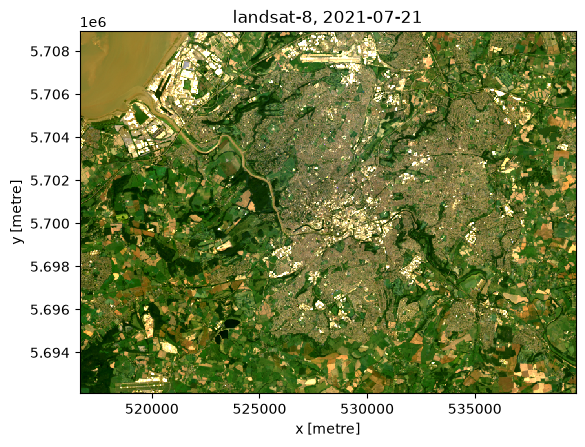

In [5]:
rgb = scene.sel(band=["red", "green", "blue"])

fig, ax = plt.subplots()
rgb.plot.imshow(ax=ax, robust=True)
ax.set_aspect("equal")
ax.set_title(f"{satellite}, {date}")
plt.show()

Now let's download the land cover map. The `io-lulc-annual-v02` dataset provides one map per calendar year, so searching within summer 2021 will return the 2021 map.

The land cover map is at 10 m resolution (it was derived from Sentinel-2 imagery), whereas our Landsat imagery is at 30 m. So, we need to resample it to match our Landsat grid using `.rio.reproject_match()`.

An important detail here is the resampling method. By default, `rioxarray` uses 'nearest neighbour' resampling, which, when going from 10 m to 30 m, simply picks the value of the 10 m pixel that is closest to the centre of the 30 m pixel. For categorical data like land cover classes, it is more sensible to use the 'mode' resampling method, which picks the most common class within each 30 m pixel. We should never use methods like 'bilinear' or 'average' on categorical data. The average of 'water' and 'urban' is not a meaningful class!


In [6]:
lulc_search = catalog.search(
    collections=["io-lulc-annual-v02"],
    bbox=bbox,
    datetime="2021-06-01/2021-08-31",
)
lulc_items = lulc_search.item_collection()
lulc_item = lulc_items[0]

print(f"Found {len(lulc_items)} item(s): {lulc_item.id}")

lulc = odc.stac.load(
    [lulc_item],
    bbox=bbox,
).squeeze()

lulc = lulc.compute()['data']

# Resample to the Landsat grid, taking the most common class in each pixel
lulc = lulc.rio.reproject_match(scene, resampling=Resampling.mode)

Found 1 item(s): 30U-2021


The original map contains nine land cover classes, each stored as an integer value (you can find the details on the [dataset page](https://planetarycomputer.microsoft.com/dataset/io-lulc-annual-v02)). Let's see which ones are in our scene, and how many pixels of each there are:

In [7]:
lulc_class_names = {
    0: "No data", 1: "Water", 2: "Trees", 4: "Flooded vegetation", 5: "Crops",
    7: "Built area", 8: "Bare ground", 9: "Snow/ice", 10: "Clouds", 11: "Rangeland",
    }

lulc_counts = pd.Series(lulc.values.ravel()).value_counts()
lulc_counts.index = lulc_counts.index.map(lulc_class_names)

lulc_counts

Built area            187651
Crops                 128669
Rangeland              59759
Trees                  33728
Water                  20807
Bare ground              166
Flooded vegetation        53
Clouds                    15
Name: count, dtype: int64

Some of these classes have very few pixels - and unsurprisingly for Bristol in July, there's no snow or ice. To keep things simple, we'll merge the land cover classes into four broader classes that cover our scene:

 1. Water
 2. Trees
 3. Grass/crops (crops, rangeland, and flooded vegetation)
 4. Urban (built area and bare ground)

Anything else (clouds and no data) will be set to `NaN`, and ignored (there's only 15 cloudy pixels anyway). We'll also set up a colour map and a small plotting function, as we'll be plotting these classes a lot.


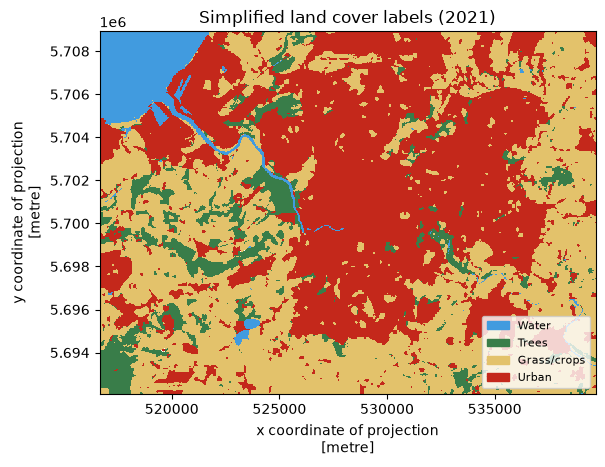

In [ ]:
# Old io-lulc class value: new class value
reclass = {1: 1, 2: 2, 4: 3, 5: 3, 11: 3, 7: 4, 8: 4}

class_names = {1: "Water", 2: "Trees", 3: "Grass/crops", 4: "Urban"}
class_colours = ["#419bdf", "#397d49", "#e3c26b", "#c4281b"]  # you can provide hex colour codes or named colours (e.g. "red", "blue", etc.) here

# Start with an array full of NaNs, and fill in each new class
labels = xr.full_like(lulc, np.nan, dtype="float32")

for old_value, new_value in reclass.items():
    labels = labels.where(lulc != old_value, new_value)


def plot_classes(da, ax, title=None):
    """Plot a classified DataArray with values 1-4 using our class colours."""
    da.plot.imshow(
        ax=ax, cmap=ListedColormap(class_colours),
        vmin=0.5, vmax=4.5, add_colorbar=False
        )
    handles = [Patch(color=c, label=class_names[i + 1]) for i, c in enumerate(class_colours)]
    ax.legend(handles=handles, loc="lower right", fontsize=8)
    ax.set_aspect("equal")
    ax.set_title(title)


fig, ax = plt.subplots()
plot_classes(labels, ax, title="Simplified land cover labels (2021)")
plt.show()

Let's save both datasets to our working directory under sensible names, as we'll be using them again in the next notebook:

In [ ]:
scene_filename = f"bristol_{date}_{satellite}.tif"
labels_filename = "bristol_2021_io-lulc-simplified.tif"

# I specify dtype="float32" here: odc-stac remembers that the original data were stored as 
# integers, and without this, our reflectance values (between 0 and 1) would also be saved as integers!
scene.rio.to_raster(scene_filename, driver="GTiff", compress="deflate", dtype="float32")
labels.rio.to_raster(labels_filename, driver="GTiff", compress="deflate", dtype="float32")

print("Saved:", scene_filename, "and", labels_filename)

Saved: bristol_2021-07-21_landsat-8.tif and bristol_2021_io-lulc-simplified.tif


## Machine learning for satellite data with `scikit-learn`

Before we start, it's worth outlining the steps of a typical supervised classification workflow for satellite imagery:

 1. Get imagery and labels. (Done above)
 2. Align the imagery and labels onto the same grid. (Done above)
 3. Reshape the data into a table of samples and features.
 4. Sample the data, and split it into training and testing datasets.
 5. Fit (train) the model on the training data.
 6. Evaluate the model on the testing data.
 7. Predict the class of every pixel in the image.
 8. Reshape the predictions back into an image.

If you've done any machine learning on tabular data before, steps 1 and 4 to 7 will look familiar. Steps 2, 3, and 8 are the 'extra' steps needed for gridded data. We've already done step 2 (with `.rio.reproject_match()`), so let's move on to step 3.

### Generate training data

First, a caveat. We are using the `io-lulc` map as our labels, which is a convenient source of global land use labels. However, it ultimately means that our model isn't really learning to classify land surfaces. It is learning to _imitate_ another machine learning model: the `io-lulc` map was itself produced by a deep learning model trained on Sentinel-2 imagery. Any errors in our training data will be inherited by our model, and any 'accuracy' we calculate is really agreement with the `io-lulc` map, not accuracy against any ground truth dataset. That's fine for this teaching example, as we're mainly interested in the practical process here. However, in a real project you would more likely create your own labels. You could do this by digitising polygons of known land cover, collecting field observations, or using an independently validated dataset.

To work with our ML data, we must reshape our data. Machine learning libraries such as `scikit-learn` aren't integrated with $n$-D image data: they expect data as a two-dimensional table, where each row is a "sample" (in our case, a pixel), and each column is a "feature" (in our case, bands). The 2-D array will have the shape `(n_samples, n_features)`. Our image is three-dimensional: `(band, y, x)`. For pixel-based classification, we need to turn our `(band, y, x)` array into a `(n_pixels, n_bands)` sized table.

We could do this with `numpy`'s `.reshape()`, but it's very easy to get the order of dimensions wrong and end up with a scrambled image. Instead, `xarray`'s `.stack()` function is designed for exactly these situations. It combines the `y` and `x` dimensions into a single new dimension (which I've called `pixel`), keeping track of the coordinates of every pixel:

In [10]:
# Stack the y and x dimensions into a single 'pixel' dimension
scene_stacked = scene.stack(pixel=("y", "x")).transpose("pixel", "band")
labels_stacked = labels.stack(pixel=("y", "x"))

scene_stacked

<xarray.DataArray (pixel: 430848, band: 5)> Size: 9MB
array([[0.11380251, 0.09408499, 0.05288999, 0.13775499, 0.1455925 ],
       [0.11457251, 0.09458001, 0.05365999, 0.13946001, 0.14361249],
       [0.1170475 , 0.09664251, 0.05486999, 0.1443275 , 0.15216501],
       ...,
       [0.0981275 , 0.09092249, 0.05220251, 0.32230753, 0.2839175 ],
       [0.070215  , 0.0766225 , 0.042165  , 0.35693002, 0.229605  ],
       [0.0469225 , 0.069225  , 0.03309   , 0.4258175 , 0.21376501]],
      shape=(430848, 5), dtype=float32)
Coordinates:
  * pixel        (pixel) object 3MB MultiIndex
  * y            (pixel) float64 3MB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (pixel) float64 3MB 5.167e+05 5.167e+05 ... 5.396e+05 5.397e+05
  * band         (band) object 40B 'red' 'green' 'blue' 'nir08' 'swir16'
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2021-07-21T11:04:43.270867
Attributes:
    long_name:  ['red', 'green', 'blue', 'nir08', 'swir16']

We now have a two-dimensional array with one row per pixel. Because it's two-dimensional, we can turn it into a `pandas` `DataFrame`, which is often easier to work with, and add the labels as an extra column. Resetting the index gives us the `y` and `x` coordinates of each pixel as columns too:

In [11]:
df = scene_stacked.to_pandas()
df["label"] = labels_stacked.values
df = df.reset_index()

# Drop any pixels that have NaN values in any band, or no label
df = df.dropna()

bands = list(scene["band"].values)

df

band,y,x,red,green,blue,nir08,swir16,label
0,5708910.0,516660.0,0.113803,0.094085,0.052890,0.137755,0.145592,1.0
1,5708910.0,516690.0,0.114573,0.094580,0.053660,0.139460,0.143612,1.0
2,5708910.0,516720.0,0.117048,0.096643,0.054870,0.144328,0.152165,1.0
3,5708910.0,516750.0,0.117048,0.096505,0.054485,0.137398,0.145070,1.0
4,5708910.0,516780.0,0.110888,0.092215,0.052643,0.123703,0.115755,1.0
...,...,...,...,...,...,...,...,...
430843,5692110.0,539550.0,0.107642,0.096560,0.057812,0.324645,0.293185,3.0
430844,5692110.0,539580.0,0.093782,0.089300,0.051515,0.319090,0.278252,3.0
430845,5692110.0,539610.0,0.098127,0.090922,0.052203,0.322308,0.283917,3.0
430846,5692110.0,539640.0,0.070215,0.076623,0.042165,0.356930,0.229605,3.0


In total, there are over 400,000 labelled pixels. We could train our model using them all, but instead we will sample a subset. There are a few reasons for this:

 - It's quicker. Training on hundreds of thousands of pixels takes a lot of time, and doesn't necessarily give a better model.
 - Neighbouring pixels are often very similar ("spatial autocorrelation"), so there is a lot of redundancy in using every single one.
 - It's more realistic. In most real projects you won't have a fully labelled map (if you already had one, why would you need to classify an image in the first place?). Instead, you'll more likely have a limited subset of labelled points or polygons. The sampling here mimics that situation.

Look at how many pixels we have in each class type:

In [12]:
df["label"].map(class_names).value_counts()

label
Grass/crops    188481
Urban          187817
Trees           33728
Water           20807
Name: count, dtype: int64

Our classes are highly _imbalanced_: there are around ten times more urban pixels than water pixels. If we took a simple random sample, our model would see very few water pixels, and would be rewarded for simply predicting 'urban' or 'grass/crops' most of the time. Instead, we'll use stratified sampling, taking the same number of pixels (500) from each class. (An alternative is to tell the model to give more weight to rare classes, using `RandomForestClassifier(class_weight="balanced")`.)

Note that I include a `random_state` seed here and throughout the rest of the notebook, wherever a random process used. Sampling and Random Forests both involve randomness, so setting a 'seed' ensures you get exactly the same results every time you run the notebook. You can use any number, but by tradition "42" is used because [Python users are nerds who like the Hitchhiker's Guide to the Galaxy books](https://en.wikipedia.org/wiki/Phrases_from_The_Hitchhiker%27s_Guide_to_the_Galaxy#The_Answer_to_the_Ultimate_Question_of_Life,_the_Universe,_and_Everything_is_42).

In [13]:
df_sample = df.groupby("label").sample(n=500, random_state=42)

df_sample["label"].map(class_names).value_counts()

label
Water          500
Trees          500
Grass/crops    500
Urban          500
Name: count, dtype: int64

At this point, we could also add extra _features_ to our table. For example, we could calculate spectral indices such as NDVI, NDWI, or NDBI,and add them as extra columns alongside the raw bands. This is known as _feature engineering_, and can sometimes improve classification performance (although equally, can sometimes make things worse). We'll stick with the raw bands here to keep things simple.

#### Splitting into training and testing data

To evaluate our model, we need to _test_ it on data that it hasn't seen during the training process. The standard approach is to randomly hold back a proportion of our samples (here, 30%) as a testing dataset.

In [14]:
X = df_sample[bands]
y = df_sample["label"]

X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
    )

(Note that we, by convention, call our features `X` and labels `y`).

However, spatial data have a particular problem: spatial autocorrelation. If we randomly split our pixels, many of our testing pixels may be very close to (and therefore very similar to) training pixels. The model is then effectively being tested on data it has already seen, and our accuracy estimate will be too optimistic. This is a form of what is known as "data leakage".

A common solution is a spatial split: rather than splitting individual pixels randomly, we divide the image into spatial blocks, and assign whole blocks to either training or testing. Here, I'll divide the image into 3 km by 3 km blocks, and use `GroupShuffleSplit` to randomly assign 30% of the blocks to testing:

In [15]:
block_size = 3000  # metres

# Give every pixel a block ID based on which 3 km x 3 km block it falls in
df_sample["block"] = (
    (df_sample["x"] // block_size).astype(int).astype(str)
    + "_"
    + (df_sample["y"] // block_size).astype(int).astype(str)
    )

splitter = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(splitter.split(df_sample, groups=df_sample["block"]))

df_train = df_sample.iloc[train_idx]
df_test = df_sample.iloc[test_idx]

X_train, y_train = df_train[bands], df_train["label"]
X_test, y_test = df_test[bands], df_test["label"]

print(f"Training samples: {len(df_train)}, testing samples: {len(df_test)}")

Training samples: 1497, testing samples: 503


Let's see what that looks like on the map:

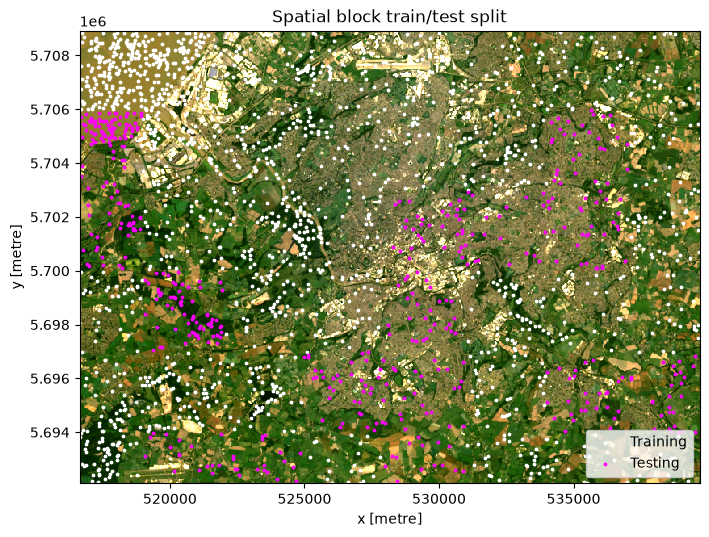

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))

rgb.plot.imshow(ax=ax, robust=True)
ax.scatter(df_train["x"], df_train["y"], s=3, c="white", label="Training")
ax.scatter(df_test["x"], df_test["y"], s=3, c="magenta", label="Testing")

ax.legend(loc="lower right")
ax.set_aspect("equal")
ax.set_title("Spatial block train/test split")
plt.show()

### Fit a Random Forest

Finally, we can train our model. A [Random Forest](https://en.wikipedia.org/wiki/Random_forest) is a collection of decision trees, each trained on a random subset of the data, which 'vote' on the final class. It's a popular choice for satellite image classification. It is robust - working well 'out of the box' without much tuning - and it is relatively hard to overfit. We'll keep the "hyperparameters" simple, using 100 trees, and set `n_jobs=-1` to use all available CPU cores (see the previous notebook!).

In `scikit-learn`, all models, including Random Forest, follow the same pattern: create the model, `.fit()` it to the training data, and then `.predict()` on new data. To compare our two splitting approaches, let's train one model on the random split, and one on the spatial split:

In [ ]:
# Train a random forest classifier on the random split
model_random = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model_random.fit(X_train_random, y_train_random)

# Train a random forest classifier on the spatial split
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Evaluate the models on their respective test sets
accuracy_random = accuracy_score(y_test_random, model_random.predict(X_test_random))
accuracy_spatial = accuracy_score(y_test, model.predict(X_test))

print(f"Accuracy (random split):  {accuracy_random:.3f}")
print(f"Accuracy (spatial split): {accuracy_spatial:.3f}")

Accuracy (random split):  0.848
Accuracy (spatial split): 0.815


The spatial split gives a lower (and probably more honest) estimate of accuracy, but in our case the difference is relatively small. This could be because our samples are spread widely across the whole image. As a result, random training and testing pixels are rarely right next to each other. The difference becomes much larger when training data are clustered: for instance, if you digitised 20 polygons, and each one contains hundreds of pixels, a random split would distribute pixels from the same polygon across both your training and testing data. 

We'll continue with the spatially split model. Overall accuracy is only one number, and it can be misleading when classes are imbalanced. A confusion matrix shows us which classes are being confused with each other:

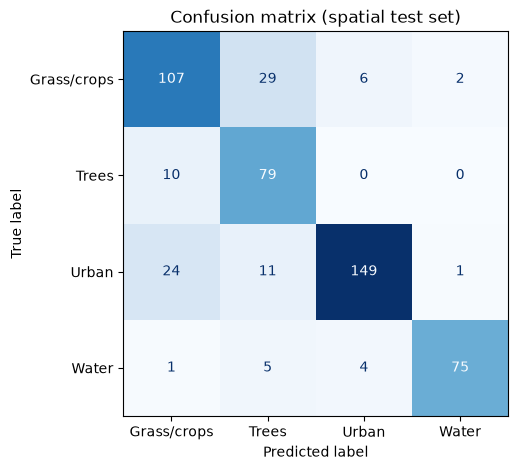

In [18]:
y_pred = model.predict(X_test)

fig, ax = plt.subplots(figsize=(5, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test.map(class_names), pd.Series(y_pred).map(class_names),
    ax=ax, cmap="Blues", colorbar=False
    )

ax.set_title("Confusion matrix (spatial test set)")
plt.show()

The `classification_report` function gives us per-class metrics. Prcision, recall, and F1-score are all different ways of balancing the amount of true positive ($TP$), false positive ($FP$), true negative ($TN$), and false negative ($FN$) classifications:

Precision asks, when a model predicts a class, how proportion of that predicition is true? 

$$ \textnormal{Precision} = \frac{TP}{TP+FP}  $$

Recall asks, out of all the actual class, what proportion is succesfully predicted by the model?

$$ \textnormal{Recall} = \frac{TP}{TP+FN} $$

The F1 score is the harmonic mean of the precision and the recall.

In [19]:
print(classification_report(y_test, y_pred, target_names=list(class_names.values())))

              precision    recall  f1-score   support

       Water       0.96      0.88      0.92        85
       Trees       0.64      0.89      0.74        89
 Grass/crops       0.75      0.74      0.75       144
       Urban       0.94      0.81      0.87       185

    accuracy                           0.82       503
   macro avg       0.82      0.83      0.82       503
weighted avg       0.84      0.82      0.82       503



Water is classified very well. This is probably unsurprising - it is spectrally very distinctive. However, as hinted at in the confusion matrix above, there is more confusion between trees and grass/crops, and between grass/crops and urban areas. This also probably makes makes sense:  trees and crops might be hard to differentiate, and within urban Bristol, there are many parks, gardens, and tree-lined streets.

A useful property of Random Forest approaches is that it can return the _feature importance_: which features the model relies on most. Permutation feautre importance is a method of measuring this, by randomly shuffling each feature in turn and measuring how much the model's accuracy drops. The bigger the drop, the more important the feature.

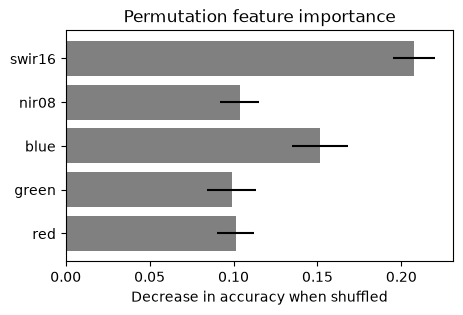

In [20]:
importance = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)

fig, ax = plt.subplots(figsize=(5, 3))

ax.barh(bands, importance.importances_mean, xerr=importance.importances_std, color="grey")
ax.set_xlabel("Decrease in accuracy when shuffled")
ax.set_title("Permutation feature importance")
plt.show()

### Classify the scene

Now that we are (relatively) happy with our model, we should try and predict the class of every pixel in the image. We must do this on a tabular version of the image, before reshape the result back into a distinct image.

Our stacked `scene_stacked` array is the appropiate object here, as it has one row per pixel. `scikit-learn` can't handle pixels that have `NaN` values, so we will only predict on valid pixels, and fill the rest with `NaN`. Because `scene_stacked` kept track of the coordinates of every pixel, we can finally simply call `.unstack()` to turn our predictions back into an image with the correct `x` and `y` coordinates.

In [21]:
# Convert to a DataFrame with the same column names as our training data
X_all = scene_stacked.to_pandas()

# Identify pixels with valid values in all bands
valid = X_all.notna().all(axis=1).values

# Create an array of NaNs, and fill in predictions for valid pixels
predictions = np.full(len(X_all), np.nan, dtype="float32")
predictions[valid] = model.predict(X_all[valid])

# Put the predictions into a DataArray with the same 'pixel' coordinates, and unstack
prediction = scene_stacked.isel(band=0, drop=True).copy(data=predictions).unstack("pixel")
prediction = prediction.transpose("y", "x")

# Remove the band names attribute inherited from the scene, and make sure the CRS is set
prediction.attrs = {}
prediction = prediction.rio.write_crs(scene.rio.crs)

prediction

<xarray.DataArray (y: 561, x: 768)> Size: 2MB
array([[1., 1., 4., ..., 4., 4., 4.],
       [1., 1., 1., ..., 4., 4., 4.],
       [1., 1., 1., ..., 4., 4., 4.],
       ...,
       [3., 3., 3., ..., 3., 3., 3.],
       [3., 3., 2., ..., 3., 3., 3.],
       [3., 3., 3., ..., 3., 3., 3.]], shape=(561, 768), dtype=float32)
Coordinates:
  * y            (y) float64 4kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 6kB 5.167e+05 5.167e+05 ... 5.396e+05 5.397e+05
    time         datetime64[ns] 8B 2021-07-21T11:04:43.270867
    spatial_ref  int64 8B 0

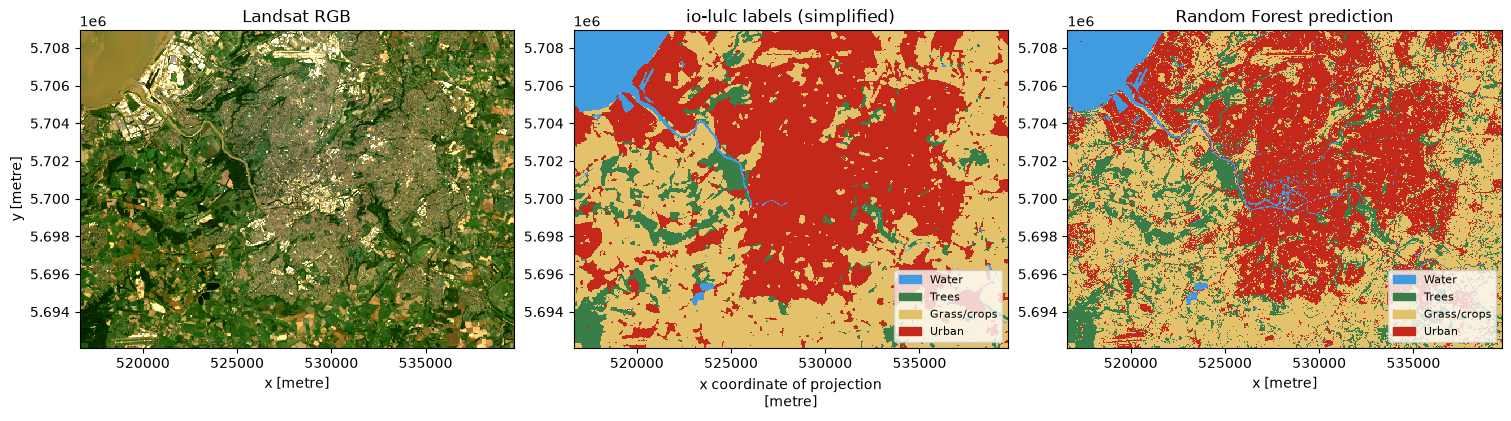

In [22]:
fig, axes = plt.subplots(ncols=3, figsize=(15, 4.5), layout="constrained")

rgb.plot.imshow(ax=axes[0], robust=True)
axes[0].set_aspect("equal")
axes[0].set_title("Landsat RGB")

plot_classes(labels, axes[1], title="io-lulc labels (simplified)")
plot_classes(prediction, axes[2], title="Random Forest prediction")

for ax in axes[1:]:
    ax.set_ylabel("")

plt.show()

Not bad! Our model has captured the broad pattern of Bristol's urban areas, the surrounding fields and woodland, the Severn Estuary, and even the River Avon.

Let's take a look at _where_ the prediction disagrees with the labels:

Agreement with io-lulc across the whole scene: 0.805


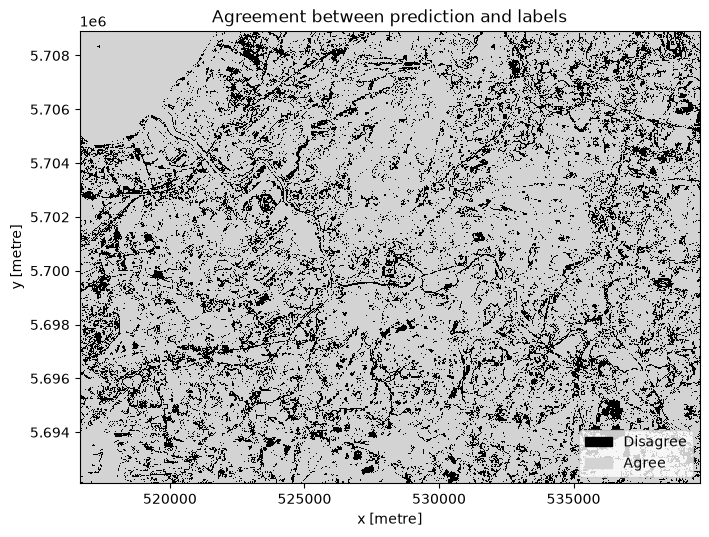

In [23]:
agreement = (prediction == labels).where(labels.notnull())

overall_agreement = float(agreement.mean())
print(f"Agreement with io-lulc across the whole scene: {overall_agreement:.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
agreement.plot.imshow(ax=ax, cmap=ListedColormap(["black", "lightgrey"]), add_colorbar=False)
ax.legend(handles=[Patch(color="black", label="Disagree"), Patch(color="lightgrey", label="Agree")], loc="lower right")
ax.set_aspect("equal")
ax.set_title("Agreement between prediction and labels")
plt.show()

Much of the disagreement is found at the edges of land cover types, as well as along narrow features such as rivers, roads, and lines of trees. This is partly 30 m Landsat pixels are large enough to contain a mixture of land cover types (e.g. part asphalt, part vegetation), as well as the fact that our labels were produced at a different resolution, by a different model, from a different satellite. 

It is worth noting that in some places, our prediction is arguably better than the labels. For instance, our model picks out much of the Floating Harbour and the River Avon through the city centre, which are largely missing from the  `io-lulc` map. This is a good reminder that input data quality is important: disagreement with the labels doesn't necessarily mean the model is wrong! 

On the other hand, you'll also notice that our prediction has a speckled 'salt-and-pepper' appearance, as each pixel is classified independently of its neighbours. Our pixel-based approach cannot 'see' surrounding pixels and incorporate them into its decision making. We'll come back to this in the next notebook.

Let's save our prediction, so we can compare it with the approaches in the next notebook:

In [24]:
prediction.rio.to_raster("bristol_2021_rf-pixel-classification.tif", driver="GTiff", compress="deflate", dtype="float32")

This is a relatively simple, single-scene example of model training, so tt's important to recognise the weaknesses in what we've done here before you try and apply this in your own work. A real-world application should take further steps. For instance:

 - As discussed above, our labels are not 'truth' but actually output of another model
 - Many of our 30 m pixels contain a mixture of land cover types.
 - For our training data, we've used a single scene from a single date, and trained and tested our model on the same image. This isn't transferrable to other images.
 - Indeed, if we applied this model to another image (e.g. in a different year, season, or area), it would almost certainly have worse peformance. Differences such as illumination, atmospheric conditions, and the types of vegetation/land surface present all change the spectral values of each class (this is known as 'domain shift') To build more generalised model, you need a wider range training data that can cover the range of conditions you want to apply it to.
 - Our spatial split is a fairly simple way to try and account for spatial auto-correlation. A more robust approach would use spatial cross-validation (repeating the split many times with different blocks).
 - We haven't performed _hyperparameter tuning_ which aims to experiment with adjusting model variables (e.g. the number of trees, or their maximum depth) to improve the quality of the model.
 - We could also explore feature engineering to improve model performance.

Some of these issues are covered in much more detail in GEOGM0053, but hopefully this gives you an idea of how the geospatial tools we've learned in this course connect to machine learning workflows.

## Other Options for Pixel-Based Classification

(NB: we are not talking about deep learning approaches, such as neural nets, just yet - we will discuss this briefly in the next section).

The Random Forest is [one of many ML classifiers](https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html) available within the `scikit-learn` package. All of them available tend to subscribe to an identical `.fit()` and `.predict()` pattern. Therefore, once you have your data in the right format and shape, you can easily swap between models - often by changing just one line. Random Forest tends to my robust first choice for ML classifiers, but there are other pixel-based classifiers that could be more appropriate for your specific needs:

 - Support Vector Machines (SVMs; see `sklearn.svm.SVC`) have historically been very popular in remote sensing, but they need features to be "scaled" (all normalised between 0 and 1) first.
 - k-Nearest Neighbours (kNN; `sklearn.neighbors.KNeighborsClassifier`) are a simple approach that classify each pixel based on the most similar training pixels.
 - Unsupervised clustering such as k-Means (e.g. `sklearn.cluster.KMeans`) don't need any labels at all. Instead, the algorithm groups pixels into clusters of similar spectral values. We can select the number of clusters: it's up to us to interpret what each cluster represents.

You aren't limited to Python and `scikit-learn`, either. Google Earth Engine has built-in classifiers, including Random Forests (`ee.Classifier.smileRandomForest`), which allow you to apply exactly this workflow at a larger scales. The GEE online documentation [has a specific machine learning guide](https://developers.google.com/earth-engine/guides/machine-learning) that you can peruse.ge

One particularly useful recent advance that you might be interested in examining are "satellite embedding" models. Satellite embeddings aim to summarise information from every possible available satellite (optical, radar, etc.) over an entire year, and summarise the information into an $n$-dimensional 'embedding' at each pixel. You can think of this, in a way, like a Principal Component Analysis (PCA): these aim to reduce a lot of input bands into a smaller amount of principal components whilst retaining the most important information. Satellite embeddings do the same, but through a deep learning approach. Google's [Satellite Embedding dataset](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL), produced by their AlphaEarth Foundations model, provides a 64-band embedding for every 10 m pixel on Earth, for every year since 2017. The idea is that rather than classifying pixels using five Landsat bands, you can classify them using these 64 embedding values, using exactly the same Random Forest workflow as above. This will often get much better results from far fewer labels. The [Earth Engine documentation has a handy guide to embeddings](https://developers.google.com/earth-engine/tutorials/community/satellite-embedding-01-introduction), and [SpatialThoughts have an embedding similarity search example](https://www.geopythontutorials.com/notebooks/xarray_embeddings_similarity_search.html) that shows how you might work with embeddings within `xarray`.

## Summary

In this notebook, we've seen how to apply a supervised machine learning classifier (a Random Forest) to satellite imagery, with a particular focus on what is 'special' about applying this to gridded geospatial data, rather than tabular data. The key steps that differ include: aligning the imagery and labels onto the same grid; reshaping the image into a table of pixels and bands; and reshaping the predictions back into an image. We also saw how spatial autocorrelation can make our accuracy estimates too optimistic, and we can help to address this using a spatial train/test split. Most importantly, this is a simplified example: just because a model can perform well on the scene it was trained upon, doesn't mean it will do well on a different image!